# Кому предложить абонемент «Зерно+»

Для директора по лояльности. Сравниваю рассылку всем активным гостям, выборочную кампанию и отказ от неё. Итоговое решение и диапазон ожидаемой маржи приведены в последнем разделе.

In [1]:
from pathlib import Path
import sys
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from statsmodels.stats.proportion import proportion_confint
RANDOM_STATE=42
DATA=Path("data")
CUTOFF="2026-07-01"
V,C=1600,150
print(sys.version.split()[0], "pandas",pd.__version__,"sklearn",sklearn.__version__)

3.12.14 pandas 3.0.6 sklearn 1.8.0


## 1. Цель

Оценить, для каких гостей дополнительная маржа за три месяца покроет рассылку. Маржа покупателя 1 600 ₽, стоимость предложения 150 ₽. Если учитывать органическую покупку, кампания окупается, когда ожидаемая добавка к вероятности покупки превышает 9,375 п.п. Порог подберу по обучающим данным и группе без предложения.

## 2. Данные

В предоставленной базе есть операции и события марта–июля, справочники и результаты июльского пилота. Единица прогноза — гость. Для исторического прогноза использую только признаки, доступные до 1 июля.

In [2]:
con=sqlite3.connect(DATA/"final1.db")
names=[r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table'")]
counts={name:con.execute('SELECT COUNT(*) FROM "'+name.replace('"','""')+'"').fetchone()[0] for name in names}
n_offer=con.execute("SELECT COUNT(*) FROM pilot WHERE group_name=?",("предложение",)).fetchone()[0]
n_july=con.execute("SELECT COUNT(*) FROM orders WHERE ordered_at>=?",("2026-07-01",)).fetchone()[0]
pilot=pd.read_sql_query("select * from pilot",con)
assert pilot.guest_id.is_unique and len(pilot)==2400
print(counts,n_offer,n_july)

{'shops': 6, 'menu': 12, 'guests': 4800, 'orders': 45629, 'order_items': 66535, 'app_sessions': 10997, 'complaints': 381, 'pilot': 2400} 1800 9714


In [3]:
a,b=pilot.bought[pilot.group_name=="предложение"],pilot.bought[pilot.group_name=="контроль"]
conv_offer,conv_ctrl=round(a.mean(),3),round(b.mean(),3)
uplift_pp=round(100*(a.mean()-b.mean()),1)
breakeven=round(C/V,3)
profit_all=V*a.sum()-C*len(a)
honest_per_offer=round((a.mean()-b.mean())*V-C)
print(conv_offer,conv_ctrl,uplift_pp,profit_all,honest_per_offer)

0.11 0.025 8.5 46800 -14


В пилоте 1 800 получателей и 600 контролей. Подписались 11,0 % и 2,5 % соответственно. Прирост 8,5 п.п. даёт −14 ₽ на одно предложение при широкой рассылке. По этой причине отдельно проверяю более узкую аудиторию.

## 3. Предобработка

Агрегирую каждую таблицу событий до гостя, затем присоединяю к полному справочнику. Срез для сессий задан как месяц строго раньше июля.

In [4]:
sql="""SELECT guest_id, COUNT(*) AS orders_n,
       julianday(:cutoff)-julianday(MAX(ordered_at)) AS recency_days,
       AVG(channel='доставка') AS delivery_share,
       AVG(strftime('%w',ordered_at) BETWEEN '1' AND '5' AND strftime('%H',ordered_at)<'10') AS morning_share
FROM orders WHERE ordered_at < :cutoff GROUP BY guest_id"""
agg=pd.read_sql_query(sql,con,params={"cutoff":CUTOFF})
def query(sql):
    return pd.read_sql_query(sql,con,params={"cutoff":CUTOFF})
data=query("""SELECT g.guest_id,g.source,g.birth_year,s.city,
              julianday(:cutoff)-julianday(g.reg_date) AS tenure_days
              FROM guests g LEFT JOIN shops s ON g.home_shop_id=s.shop_id""")
order_more=query("""SELECT guest_id,avg(amount) AS avg_check,count(DISTINCT shop_id) AS shops_n
                    FROM orders WHERE ordered_at<:cutoff GROUP BY guest_id""")
menu_share=query("""SELECT o.guest_id,avg(m.category='кофе') AS coffee_share
                    FROM orders o JOIN order_items i ON o.order_id=i.order_id
                    JOIN menu m ON i.item_id=m.item_id WHERE o.ordered_at<:cutoff GROUP BY o.guest_id""")
sessions=query("""SELECT guest_id,sum(sessions) AS app_sessions FROM app_sessions
                  WHERE month<substr(:cutoff,1,7) GROUP BY guest_id""")
complaints=query("""SELECT guest_id,count(*) AS complaints_n FROM complaints
                    WHERE created_at<:cutoff GROUP BY guest_id""")
for part in [agg,order_more,menu_share,sessions,complaints]:
    before=len(data)
    data=data.merge(part,on="guest_id",how="left",validate="one_to_one")
    assert len(data)==before and data.guest_id.is_unique
for col in ["orders_n","shops_n","app_sessions","complaints_n"]:
    data[col]=data[col].fillna(0)
weeks=data.tenure_days.clip(upper=122)/7
data["orders_per_week"]=data.orders_n.div(weeks.where(weeks>0)).fillna(0)
pilot_joined=pilot.merge(data,on="guest_id",how="left",validate="one_to_one")
assert len(pilot_joined)==len(pilot) and pilot_joined.city.notna().all()
off=pilot_joined[pilot_joined.group_name=="предложение"].reset_index(drop=True)
ctrl=pilot_joined[pilot_joined.group_name=="контроль"].reset_index(drop=True)
print(len(data),int((data.orders_n>0).sum()),len(off),len(ctrl))
print(data[["orders_n","orders_per_week","app_sessions"]].mean())

4800 4387 1800 600
orders_n            7.482292
orders_per_week     0.473114
app_sessions       15.575833
dtype: float64


In [5]:
ss=pd.read_sql_query("SELECT guest_id, AVG(payment='абонемент') AS sub_share FROM orders GROUP BY guest_id",con)
l=off.merge(ss,on="guest_id",how="left",validate="one_to_one")
sub_share=l.sub_share.fillna(0)
auc_leak,auc_clean=round(roc_auc_score(l.bought,sub_share),3),round(roc_auc_score(l.bought,l.orders_per_week),3)
n_sub_nonbuyers=((l.bought==0)&(sub_share>0)).sum()
print(auc_leak,auc_clean,n_sub_nonbuyers)
con.close()

0.891 0.591 0


Получилось 4 800 гостей, из них у 4 387 есть заказы в окне. Соединения сохранили число гостей. Гостям без жалоб или сессий записал ноль; средний чек у гостей без заказов оставил неизвестным. Диагностика июльских оплат показала следствие покупки абонемента. Использую эту информацию только для демонстрации утечки.

## 4. Анализ и модели

morning_share
до 0.2      0.033
0.2–0.5     0.082
выше 0.5    0.273
Name: bought, dtype: float64 440 2.48
source
касса         0.087
приложение    0.143
Name: bought, dtype: float64 city
Казань    0.125
Пермь     0.118
Тюмень    0.060
Уфа       0.105
Name: bought, dtype: float64


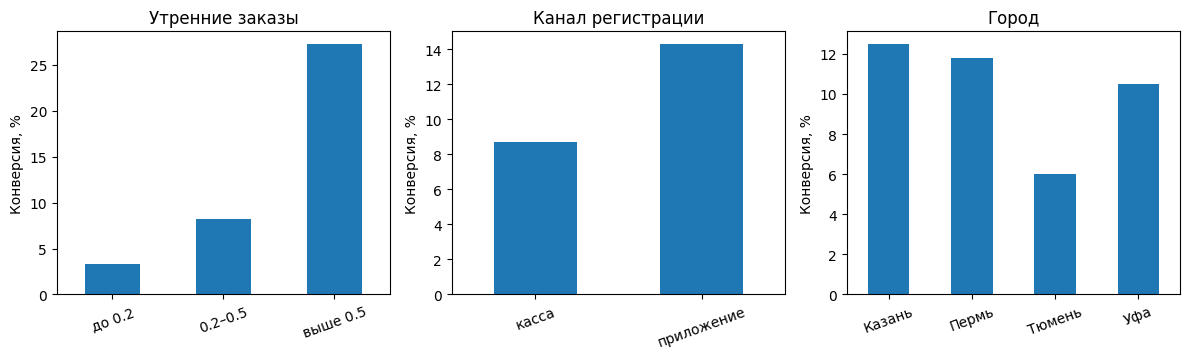

In [6]:
bands=pd.cut(off.morning_share,[0,.2,.5,1],include_lowest=True,labels=["до 0.2","0.2–0.5","выше 0.5"])
by_morning=off.bought.groupby(bands,observed=True).mean().round(3)
by_source=off.groupby("source").bought.mean().round(3)
by_city=off.groupby("city").bought.mean().round(3)
top=bands=="выше 0.5"
n_top=top.sum()
lift_top=round(off.loc[top,"bought"].mean()/off.bought.mean(),2)
print(by_morning,n_top,lift_top)
print(by_source,by_city)
fig,axes=plt.subplots(1,3,figsize=(12,3.7))
for ax,values,title in zip(axes,[by_morning,by_source,by_city],["Утренние заказы","Канал регистрации","Город"]):
    values.mul(100).plot.bar(ax=ax,rot=20)
    ax.set(title=title,xlabel="",ylabel="Конверсия, %")
fig.tight_layout()
plt.show()

В верхней утренней группе 440 гостей, конверсия 27,3 % против 3,3 % в нижней. Через приложение конверсия 14,3 %, через кассу 8,7 %. В Тюмени 6,0 %, в Казани 12,5 %. В выборе признаков эти различия рассматриваю как наблюдаемые связи.

In [7]:
num = ["orders_n", "orders_per_week", "recency_days", "avg_check", "delivery_share", "morning_share",
       "shops_n", "tenure_days", "coffee_share", "app_sessions", "complaints_n"]
cat = ["source", "city"]
X, y = off[num + cat], off["bought"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scaled = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
    (OneHotEncoder(handle_unknown="ignore"), cat))
plain = make_column_transformer(
    (SimpleImputer(strategy="median"), num),
    (OneHotEncoder(handle_unknown="ignore"), cat))

models={"константа":make_pipeline(plain,DummyClassifier()),"логрегрессия":make_pipeline(scaled,LogisticRegression(max_iter=1000)),"лес":make_pipeline(plain,RandomForestClassifier(n_estimators=100,max_depth=8,min_samples_leaf=10,random_state=RANDOM_STATE)),"бустинг":make_pipeline(plain,HistGradientBoostingClassifier(max_depth=3,learning_rate=.05,max_iter=200,random_state=RANDOM_STATE))}
rows=[]
for name,m in models.items():
    v=cross_val_score(m,X_train,y_train,cv=cv,scoring="roc_auc")
    rows.append([name,v.mean(),v.std()])
cv_table=pd.DataFrame(rows,columns=["model","auc_mean","auc_std"]).round(3)
best_name=cv_table.loc[cv_table.auc_mean.idxmax(),"model"]
cv_table

,model,auc_mean,auc_std
0,константа,0.500,0.000
1,логрегрессия,0.827,0.028
2,лес,0.796,0.032
3,бустинг,0.817,0.023


Средний CV-AUC у константы 0,500, у логистической регрессии 0,827, леса 0,796, бустинга 0,817. Для прогноза выбираю логистическую регрессию. Её отрыв от бустинга меньше межфолдового SD 0,028, поэтому преимущество по качеству предварительное.

0.08 0.08


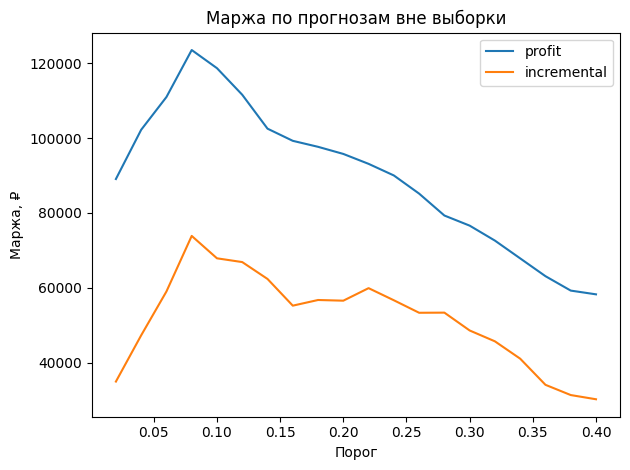

In [8]:
best=clone(models[best_name])
def profit_curve(p,y,value=1600,cost=150):
    rows=[]
    for t in np.arange(.02,.41,.02).round(2):
        selected=p>t
        buyers=y[selected].sum()
        rows.append([t,selected.sum(),buyers,value*buyers-cost*selected.sum()])
    return pd.DataFrame(rows,columns=["threshold","sent","buyers","profit"])
oof=cross_val_predict(best,X_train,y_train,cv=cv,method="predict_proba")[:,1]
curve=profit_curve(oof,y_train)
best_t=curve.loc[curve.profit.idxmax(),"threshold"]
best.fit(X_train,y_train)

p_ctrl=best.predict_proba(ctrl[num+cat])[:,1]
def incremental(t):
    sel=oof>t
    organic_rate=ctrl.bought[p_ctrl>t].mean()
    return V*(y_train[sel].sum()-organic_rate*sel.sum())-C*sel.sum()
curve["incremental"]=curve.threshold.map(incremental)
best_t_incr=curve.loc[curve.incremental.idxmax(),"threshold"]
print(best_t,best_t_incr)
curve.set_index("threshold")[["profit","incremental"]].plot(xlabel="Порог",ylabel="Маржа, ₽",title="Маржа по прогнозам вне выборки")
plt.tight_layout()
plt.show()

In [9]:
p_test=best.predict_proba(X_test)[:,1]
flag=p_test>best_t_incr
test_sent,test_buyers=int(flag.sum()),int(y_test[flag].sum())
test_profit=V*test_buyers-C*test_sent
all_profit=V*y_test.sum()-C*len(y_test)
test_auc=roc_auc_score(y_test,p_test)
print(test_auc,test_sent,test_buyers,test_profit,all_profit)

0.8682375693419512 174 42 41100 10900


По прогнозам вне выборки обе кривые достигают максимума при пороге 0,08. На тесте ROC-AUC 0,868. Среди 174 получателей было 42 покупателя, валовая оценка 41 100 ₽ против 10 900 ₽ при рассылке всем. Для решения ниже вычитаю органические покупки.

In [10]:
final=clone(best).fit(X,y)
cols=["orders_per_week","morning_share","delivery_share","recency_days","coffee_share","app_sessions"]
rest=data[(~data.guest_id.isin(pilot.guest_id))&(data.orders_n>0)].copy()
rest["p"]=final.predict_proba(rest[num+cat])[:,1]
rest["send"]=rest.p>best_t
n_rest,n_send=len(rest),rest.send.sum()
portrait=rest.groupby("send")[cols].mean().round(3)
app_share=round((rest.source[rest.send]=="приложение").mean(),3)
print(n_rest,n_send,app_share)
portrait

1987 792 0.529


,orders_per_week,morning_share,delivery_share,recency_days,coffee_share,app_sessions
send,,,,,,
False,0.442,0.213,0.165,31.550,0.524,13.802
True,0.670,0.576,0.054,14.186,0.590,19.783


In [11]:
pg=cross_val_predict(best,X,y,cv=cv,method="predict_proba")[:,1]
flags=pd.Series(pg>best_t,index=off.index)
ages=2026-off.birth_year.replace(1900,np.nan)
ag=pd.cut(ages,[0,29,49,200],labels=["до 30","30–49","50+"])
sel_by_city=flags.groupby(off.city).mean().round(3)
recall_by_city=flags[y==1].groupby(off.city).mean().round(3)
weak_city=recall_by_city.idxmin()
recall_by_age=flags[y==1].groupby(ag,observed=True).mean().round(3)
def summary(group):
    rows={}
    for group_name,indices in group.groupby(group,observed=True).groups.items():
        chosen=flags.loc[indices]
        outcome=y.loc[indices]
        rows[group_name]=[len(indices),outcome.sum(),chosen.mean(),chosen[outcome==1].mean(),roc_auc_score(outcome,pd.Series(pg,index=y.index).loc[indices])]
    return pd.DataFrame.from_dict(rows,orient="index",columns=["n","купили","отбор","полнота","AUC"]).round(3)
display(summary(off.city))
display(summary(ag.dropna()))
print("Возраст неизвестен",ag.isna().sum())

,n,купили,отбор,полнота,AUC
Казань,729,91,0.440,0.890,0.835
Пермь,570,67,0.414,0.836,0.830
Тюмень,282,17,0.206,0.647,0.820
Уфа,219,23,0.388,0.957,0.867


,n,купили,отбор,полнота,AUC
до 30,470,48,0.379,0.896,0.876
30–49,987,110,0.395,0.836,0.820
50+,156,20,0.385,0.900,0.867


Возраст неизвестен 187


В отобранном сегменте 57,6 % заказов приходятся на будни до 10 утра, 5,4 % составляют доставки. В среднем гости заказывали 0,67 раза в неделю и последний раз были 14 дней назад. В Тюмени поймано 64,7 % покупателей, в других городах 83,6–95,7 %. Возраст в признаки не входил. У групп 50+ всего 20 покупок, а у 187 участников возраст неизвестен.

In [12]:
rest["send"]=rest.p>best_t_incr
n_send=rest.send.sum()
v=final.predict_proba(ctrl[num+cat])[:,1]>best_t_incr
a=ctrl.bought[v].mean()
organic=round(a,3)
buyers=rest.p[rest.send].sum()
exp_buyers=round(buyers,1)
naive_profit=round(1600*buyers-150*n_send)
honest_profit=round(1600*(buyers-a*n_send)-150*n_send)
honest_all=round(1600*(rest.p.sum()-ctrl.bought.mean()*len(rest))-150*len(rest))
selected_ctrl=ctrl.loc[v,"bought"]
wilson_lo,wilson_hi=proportion_confint(selected_ctrl.sum(),len(selected_ctrl),method="wilson")
margin_lo=V*(buyers-wilson_hi*n_send)-C*n_send
margin_hi=V*(buyers-wilson_lo*n_send)-C*n_send
print("Кандидаты, отбор, покупки",len(rest),n_send,exp_buyers)
print("Контроль",len(selected_ctrl),selected_ctrl.sum(),organic)
print("Ожидаемая дополнительная маржа",honest_profit,"границы по контролю",round(margin_lo),round(margin_hi),"рассылка всем",honest_all)
print("Без поправки",naive_profit)
rest.loc[rest.send,["guest_id","p"]].sort_values("p",ascending=False).to_csv(DATA/"autumn-candidates.csv",index=False)

Кандидаты, отбор, покупки 1987 792 205.9
Контроль 245 14 0.057
Ожидаемая дополнительная маржа 138160 границы по контролю 91939 167056 рассылка всем 5940
Без поправки 210572


**Вывод по экономике.** Оценка для 792 получателей с учётом 14 покупок в выбранной части контроля — 138 160 ₽ дополнительной маржи. Без вычета органических покупок получилось бы 210 572 ₽. Рассылка всем 1 987 кандидатам даёт лишь 5 940 ₽. Интервал Уилсона для контрольной доли даёт условные границы от 91 939 до 167 056 ₽ для выбранной рассылки.

## 5. Выводы и рекомендации

В июльском пилоте предложение получили 1 800 гостей, контроль составил 600. Широкая рассылка дала −14 ₽ на предложение после вычета органических покупок. При пороге 0,08 в аудиторию входят 792 из 1 987 активных гостей вне пилота. Прогноз — около 206 покупок, из них примерно 45 состоялись бы без предложения. Ожидаемая дополнительная маржа — около 138 тыс. ₽ за три месяца. Разброс одной только органической доли даёт ориентир около 90–170 тыс. ₽; сезон и ошибка прогноза в эти границы не входят.

Для осенней кампании нужно обновить признаки к фактической дате решения и оставить случайный контроль внутри отобранного сегмента. Результаты июля особенно осторожно переношу на Тюмень и на гостей с неизвестным возрастом. Полезно проверить калибровку по городам до расширения кампании.